In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
from pathlib import Path

DATASET = Path("/content/drive/MyDrive/beealarmed/yolo_v1")

print("Dataset:", DATASET.exists())

for path in [
    DATASET / "data.yaml",
    DATASET / "images" / "train",
    DATASET / "images" / "val",
    DATASET / "images" / "predict",
    DATASET / "labels" / "train",
    DATASET / "labels" / "val",
]:
    if path.is_dir():
        cantidad = sum(1 for p in path.iterdir() if p.is_file())
        print(f"{path.relative_to(DATASET)}: folder found ({cantidad} files)")
    else:
        print(f"{path.relative_to(DATASET)}: {'file found' if path.is_file() else 'NOT FOUND'}")

Dataset: True
data.yaml: file found
images/train: folder found (570 files)
images/val: folder found (143 files)
images/predict: folder found (1503 files)
labels/train: folder found (570 files)
labels/val: folder found (143 files)


**Setting YOVOv1 for annotation assistance** for BeeAlarmed Dataset

In [7]:
%pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 44.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 10.7 MB/s eta 0:00:00


In [ ]:
%pip install -q onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 43.4 MB/s eta 0:00:00


In [4]:
import torch
import ultralytics

print("Ultralytics:", ultralytics.__version__)
print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.177
GPU disponible: True
GPU: Tesla T4


In [ ]:
from pathlib import Path

DATASET = Path("/content/drive/MyDrive/beealarmed/yolo_v1")
yaml_path = DATASET / "data.yaml"

print(yaml_path.read_text(encoding="utf-8"))

path: .
train: images/train
val: images/val

names:
  0: bee
  1: varroa
  2: wasp



In [ ]:
from pathlib import Path

for split in ("train", "val"):
    images_dir = DATASET / "images" / split
    labels_dir = DATASET / "labels" / split

    images = [
        p for p in images_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
    ]
    labels = list(labels_dir.glob("*.txt"))

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Tag files:", len(labels))


TRAIN
Images: 570
Tag files: 570

VAL
Images: 143
Tag files: 143


In [ ]:
import shutil
from pathlib import Path

DATASET = Path("/content/drive/MyDrive/beealarmed/yolo_v1")
LOCAL_DATASET = Path("/content/beealarmed_yolo_train")

if LOCAL_DATASET.exists():
    shutil.rmtree(LOCAL_DATASET)

for split in ("train", "val"):
    for kind in ("images", "labels"):
        source = DATASET / kind / split
        destination = LOCAL_DATASET / kind / split

        shutil.copytree(source, destination)

yaml_content = f"""
path: {LOCAL_DATASET}
train: images/train
val: images/val

names:
  0: bee
  1: varroa
  2: wasp
"""

yaml_path = LOCAL_DATASET / "data.yaml"
yaml_path.write_text(yaml_content.strip() + "\n", encoding="utf-8")

print("Dataset local:", LOCAL_DATASET)
print("Configuración:\n")
print(yaml_path.read_text(encoding="utf-8"))

Dataset local: /content/beealarmed_yolo_train
Configuración:

path: /content/beealarmed_yolo_train
train: images/train
val: images/val

names:
  0: bee
  1: varroa
  2: wasp



In [ ]:
#--- Training
from ultralytics import YOLO
import torch

assert torch.cuda.is_available(), "GPU not detected"
assert (LOCAL_DATASET / "data.yaml").exists(), "data.yaml not found"

model = YOLO("yolo11n.pt")

results = model.train(
    data=str(LOCAL_DATASET / "data.yaml"),
    epochs=80,
    patience=15,
    imgsz=960,
    batch=4,
    device=0,
    workers=2,
    seed=42,
    project="/content/runs",
    name="beearmaled_yolo11n_v1",
    exist_ok=True,
    plots=True,
    save=True
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/beealarmed_yolo_train/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=beearmaled_yolo11n_v1, nbs=64, nms=None, opset=Non

In [ ]:
#--- Saving best epoch (model) out of the 80 epochs
from pathlib import Path
import shutil

BEST_MODEL = Path(
    "/content/runs/beearmaled_yolo11n_v1/weights/best.pt"
)

OUTPUT_DIR = Path("/content/drive/MyDrive/beealarmed/models")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DESTINATION = OUTPUT_DIR / "beearmaled_yolo11n_v1_best.pt"

if BEST_MODEL.exists():
    shutil.copy2(BEST_MODEL, DESTINATION)
    print("Model saved:", DESTINATION)
else:
    print("best.pt not found")

Model saved: /content/drive/MyDrive/beealarmed/models/beearmaled_yolo11n_v1_best.pt


In [ ]:
#--- Validation
DATASET = Path("/content/drive/MyDrive/beealarmed/yolo_v1")
LOCAL_DATASET = Path("/content/beealarmed_yolo_train")
MODEL_PATH = Path(
    "/content/drive/MyDrive/beealarmed/models/beearmaled_yolo11n_v1_best.pt"
)

model = YOLO(str(MODEL_PATH))

metrics = model.val(
    data=str(LOCAL_DATASET / "data.yaml"),
    imgsz=960,
    batch=4,
    device=0,
    plots=True,
    project="/content/runs",
    name="validation_v1",
    exist_ok=True
)

print("\n===== VALIDATION RESULTS=====")
print(f"mean precision: {metrics.box.mp:.4f}")
print(f"mean recall:    {metrics.box.mr:.4f}")
print(f"mAP@50:          {metrics.box.map50:.4f}")
print(f"mAP@50-95:       {metrics.box.map:.4f}")

# Métricas por clase
print("\n===== PER CLASS RESULTS =====")
for i, class_id in enumerate(metrics.box.ap_class_index):
    class_name = model.names[int(class_id)]
    ap50 = metrics.box.ap50[i]
    print(f"{class_name}: AP@50 = {ap50:.4f}")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 486.3±146.9 MB/s, size: 13.8 KB)
val: Scanning /content/beealarmed_yolo_train/labels/val.cache... 143 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 143/143 28.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 10.1it/s 3.6s
                   all        143        183      0.995          1      0.995      0.762
                   bee         44         44      0.991          1      0.995      0.841
                varroa         39         40      0.998          1      0.995      0.636
                  wasp         99         99      0.996          1      0.995       0.81
Speed: 3.9ms preprocess, 9.5ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to /content/runs/validatio


image 1/143 /content/beealarmed_yolo_train/images/val/varroa__0JXDDXuZX59ezm6L4uyaostpDtSU3vJG.jpeg: 960x480 1 bee, 1 varroa, 12.4ms
image 2/143 /content/beealarmed_yolo_train/images/val/varroa__0TIPAFYGlPAOOLrLsXvpdezEXTi1FTa3.jpeg: 960x480 1 bee, 1 varroa, 13.4ms
image 3/143 /content/beealarmed_yolo_train/images/val/varroa__0dFkZmihcjYhNI3ycqjLSqFyrCqZayEg.jpeg: 960x480 1 bee, 1 varroa, 14.7ms
image 4/143 /content/beealarmed_yolo_train/images/val/varroa__0qBqWmYYcbS6RAXLRIXvG0S6FfInWFvq.jpeg: 960x480 1 bee, 1 varroa, 17.9ms
image 5/143 /content/beealarmed_yolo_train/images/val/varroa__15Ke3HzlJyVMyQWTNn6RM5aBdYwgEzHB.jpeg: 960x480 1 bee, 1 varroa, 12.5ms
image 6/143 /content/beealarmed_yolo_train/images/val/varroa__19LDn2n70LliDkdzTHJwHoSZAurbnyjO.jpeg: 960x480 1 bee, 1 varroa, 12.4ms
image 7/143 /content/beealarmed_yolo_train/images/val/varroa__1FDxezEkPymmXP8HSIzMCo3uH37pPzZ5.jpeg: 960x480 1 bee, 1 varroa, 12.4ms
image 8/143 /content/beealarmed_yolo_train/images/val/varroa__1GDzNs

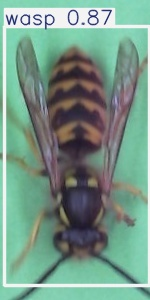

varroa__1GDzNsNOCRONuiExD59HUX5nFXqoVUur.jpg


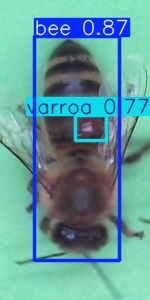

wasps__PWXSt9Oe1FAZRgbRXWcdDVMNmCEAPLpR.jpg


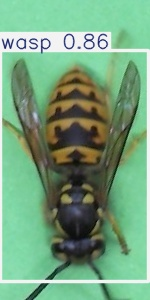

varroa__22ELIfUHxVP5YeygW8tcR3mZCkYr4Tuw.jpg


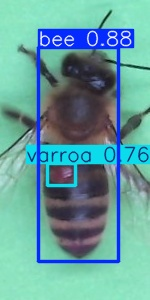

wasps__9R583etpBBrpE0Aufg9mvUpp4DENGBrm.jpg


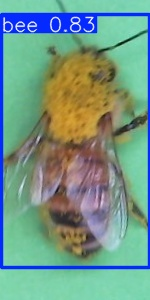

wasps__4tsR0xcSm96jh4PUcv5lyL6PbVSvEmTc.jpg


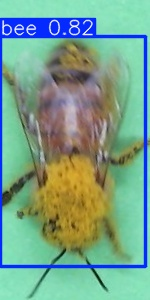

In [ ]:
from IPython.display import display
from PIL import Image
import random

MODEL_PATH = Path(
    "/content/drive/MyDrive/beealarmed/models/beearmaled_yolo11n_v1_best.pt"
)
VAL_IMAGES = Path("/content/beealarmed_yolo_train/images/val")

model = YOLO(str(MODEL_PATH))

model.predict(
    source=str(VAL_IMAGES),
    imgsz=960,
    conf=0.25,
    device=0,
    save=True,
    project="/content/runs",
    name="val_predictions_review",
    exist_ok=True
)

OUTPUT = Path("/content/runs/val_predictions_review")
images = [
    p for p in OUTPUT.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

random.seed(98)
for path in random.sample(images, min(6, len(images))):
    print(path.name)
    display(Image.open(path))

ANNOTATION / BOUNDING BOX PREDICTION

In [9]:
#--- Prediction
from pathlib import Path
from collections import Counter
from ultralytics import YOLO
import shutil

from google.colab import drive
drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/beealarmed")

MODEL_PATH = BASE / "models" / "beearmaled_yolo11n_v1_best.pt"
SOURCE = BASE / "yolo_v1" / "images" / "predict"
OUTPUT = BASE / "yolo_v1" / "predict_v2"

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"No se encontró el modelo: {MODEL_PATH}")

if not SOURCE.exists():
    raise FileNotFoundError(f"No se encontró la carpeta: {SOURCE}")

images = sorted(
    p for p in SOURCE.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)

if not images:
    raise RuntimeError(f"No hay imágenes en {SOURCE}")

IMAGES_OUT = OUTPUT / "images"
LABELS_OUT = OUTPUT / "labels"
IMAGES_OUT.mkdir(parents=True, exist_ok=True)
LABELS_OUT.mkdir(parents=True, exist_ok=True)

model = YOLO(str(MODEL_PATH))

print("Modelo:", MODEL_PATH)
print("Fuente:", SOURCE)
print("Imágenes:", len(images))
print("Clases:", model.names)

CONF = 0.25
IOU = 0.45
IMGSZ = 640

class_counts = Counter()
total_boxes = 0
used_names = set()

for i, image_path in enumerate(images, start=1):
    #--- Evitar colisiones de nombres si hay subcarpetas.
    relative = image_path.relative_to(SOURCE)
    prefix = relative.parent.as_posix().replace("/", "__")
    stem = f"{prefix}__{image_path.stem}" if prefix != "." else image_path.stem

    if stem in used_names:
        raise ValueError(f"Nombre de imagen duplicado: {stem}")
    used_names.add(stem)

    result = model.predict(
        source=str(image_path),
        conf=CONF,
        iou=IOU,
        imgsz=IMGSZ,
        verbose=False
    )[0]

    shutil.copy2(image_path, IMAGES_OUT / f"{stem}{image_path.suffix.lower()}")

    lines = []
    if result.boxes is not None and len(result.boxes) > 0:
        xywhn = result.boxes.xywhn.cpu().tolist()
        classes = result.boxes.cls.cpu().tolist()

        for cls, (x, y, w, h) in zip(classes, xywhn):
            cls = int(cls)
            lines.append(f"{cls} {x:.6f} {y:.6f} {w:.6f} {h:.6f}")
            class_counts[cls] += 1
            total_boxes += 1

    (LABELS_OUT / f"{stem}.txt").write_text(
        "\n".join(lines) + ("\n" if lines else ""),
        encoding="utf-8"
    )

    if i % 100 == 0 or i == len(images):
        print(f"Procesadas: {i}/{len(images)}")

print("\n--- Resultado ---")
print("Imágenes procesadas:", len(images))
print("Etiquetas creadas:", len(list(LABELS_OUT.glob("*.txt"))))
print("Cajas detectadas:", total_boxes)
print("Cajas por ID de clase:", dict(sorted(class_counts.items())))
print("Salida:", OUTPUT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Modelo: /content/drive/MyDrive/beealarmed/models/beearmaled_yolo11n_v1_best.pt
Fuente: /content/drive/MyDrive/beealarmed/yolo_v1/images/predict
Imágenes: 1503
Clases: {0: 'bee', 1: 'varroa', 2: 'wasp'}
Procesadas: 100/1503
Procesadas: 200/1503
Procesadas: 300/1503
Procesadas: 400/1503
Procesadas: 500/1503
Procesadas: 600/1503
Procesadas: 700/1503
Procesadas: 800/1503
Procesadas: 900/1503
Procesadas: 1000/1503
Procesadas: 1100/1503
Procesadas: 1200/1503
Procesadas: 1300/1503
Procesadas: 1400/1503
Procesadas: 1500/1503
Procesadas: 1503/1503

--- Resultado ---
Imágenes procesadas: 1503
Etiquetas creadas: 1503
Cajas detectadas: 2572
Cajas por ID de clase: {0: 1075, 1: 1050, 2: 447}
Salida: /content/drive/MyDrive/beealarmed/yolo_v1/predict_v2


In [10]:
#Validating format for labels
from pathlib import Path
from collections import Counter

BASE = Path("/content/drive/MyDrive/beealarmed")
OUTPUT = BASE / "yolo_v1" / "predict_v2"

IMAGES = OUTPUT / "images"
LABELS = OUTPUT / "labels"
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

images = {
    p.stem: p
    for p in IMAGES.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
}

labels = {
    p.stem: p
    for p in LABELS.glob("*.txt")
}

missing_labels = sorted(set(images) - set(labels))
orphan_labels = sorted(set(labels) - set(images))

class_counts = Counter()
empty_labels = 0
invalid_lines = []

for stem, label_path in labels.items():
    lines = [
        line.strip()
        for line in label_path.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]

    if not lines:
        empty_labels += 1

    for line_number, line in enumerate(lines, start=1):
        parts = line.split()

        try:
            if len(parts) != 5:
                raise ValueError("Debe contener 5 campos")

            cls = int(parts[0])
            x, y, w, h = map(float, parts[1:])

            if cls not in (0, 1, 2):
                raise ValueError(f"Clase inesperada: {cls}")

            if not all(0 <= v <= 1 for v in (x, y, w, h)):
                raise ValueError("Coordenadas fuera del rango 0–1")

            if w <= 0 or h <= 0:
                raise ValueError("Ancho o alto no positivo")

            class_counts[cls] += 1

        except Exception as e:
            invalid_lines.append((stem, line_number, str(e), line))

print("=== VALIDACIÓN DE predict_v2 ===")
print("Imágenes:", len(images))
print("Archivos de etiquetas:", len(labels))
print("Imágenes sin etiqueta:", len(missing_labels))
print("Etiquetas sin imagen:", len(orphan_labels))
print("Archivos de etiquetas vacíos:", empty_labels)
print("Líneas inválidas:", len(invalid_lines))
print("Cajas por clase:", dict(sorted(class_counts.items())))
print("Clases: 0=bee, 1=varroa, 2=wasp")

if missing_labels:
    print("\nEjemplos de imágenes sin etiqueta:", missing_labels[:10])

if orphan_labels:
    print("\nEjemplos de etiquetas sin imagen:", orphan_labels[:10])

if invalid_lines:
    print("\nEjemplos de líneas inválidas:")
    for item in invalid_lines[:10]:
        print(item)

=== VALIDACIÓN DE predict_v2 ===
Imágenes: 1503
Archivos de etiquetas: 1503
Imágenes sin etiqueta: 0
Etiquetas sin imagen: 0
Archivos de etiquetas vacíos: 0
Líneas inválidas: 0
Cajas por clase: {0: 1075, 1: 1050, 2: 447}
Clases: 0=bee, 1=varroa, 2=wasp


**Exporting back for manual inspection of BB in CVAT**

In [11]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import yaml

BASE = Path("/content/drive/MyDrive/beealarmed")
SOURCE = BASE / "yolo_v1" / "predict_v2"
OUTPUT_ZIP = BASE / "yolo_v1" / "predict_v2_cvat.zip"

IMAGES = SOURCE / "images"
LABELS = SOURCE / "labels"

image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

images = sorted(
    p for p in IMAGES.iterdir()
    if p.is_file() and p.suffix.lower() in image_exts
)

# Comprobar que todas las imágenes tienen su etiqueta.
for image_path in images:
    label_path = LABELS / f"{image_path.stem}.txt"
    if not label_path.exists():
        raise FileNotFoundError(f"Falta la etiqueta de {image_path.name}")

if not images:
    raise RuntimeError("No se encontraron imágenes.")

# Estructura compatible con Ultralytics YOLO Detection.
data_yaml = {
    "path": ".",
    "train": "train.txt",
    "names": {
        0: "bee",
        1: "varroa",
        2: "wasp",
    },
}

with ZipFile(OUTPUT_ZIP, "w", ZIP_DEFLATED) as z:
    z.writestr(
        "data.yaml",
        yaml.safe_dump(data_yaml, sort_keys=False, allow_unicode=True)
    )

    train_list = []

    for image_path in images:
        image_rel = f"train/images/{image_path.name}"
        label_rel = f"train/labels/{image_path.stem}.txt"

        z.write(image_path, image_rel)
        z.write(LABELS / f"{image_path.stem}.txt", label_rel)

        train_list.append(image_rel)

    z.writestr("train.txt", "\n".join(train_list) + "\n")

print("ZIP creado:", OUTPUT_ZIP)
print("Imágenes incluidas:", len(images))
print("Etiquetas incluidas:", len(images))
print("Tamaño (MB):", round(OUTPUT_ZIP.stat().st_size / (1024**2), 2))

ZIP creado: /content/drive/MyDrive/beealarmed/yolo_v1/predict_v2_cvat.zip
Imágenes incluidas: 1503
Etiquetas incluidas: 1503
Tamaño (MB): 20.53


Once confirmed the full dataset will be composed of manual + YOLO-assisted annotations.

In [13]:
from pathlib import Path
import shutil
import yaml

BASE = Path("/content/drive/MyDrive/beealarmed")
V1 = BASE / "yolo_v1"
PRED = V1 / "predict_v2"
V2 = BASE / "yolo_v2"

EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Evitar sobrescribir una versión anterior.
if V2.exists():
    raise FileExistsError(
        f"Ya existe {V2}. No se modificó."
    )

manual_images = V1 / "images"
manual_labels = V1 / "labels"
pred_images = PRED / "images"
pred_labels = PRED / "labels"

for p in [
    manual_images / "train",
    manual_images / "val",
    manual_labels / "train",
    manual_labels / "val",
    pred_images,
    pred_labels,
]:
    if not p.is_dir():
        raise FileNotFoundError(f"No existe la carpeta: {p}")

def get_images(folder):
    return sorted(
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in EXTS
    )

def copy_split(src_images, src_labels, dst_images, dst_labels):
    dst_images.mkdir(parents=True, exist_ok=True)
    dst_labels.mkdir(parents=True, exist_ok=True)

    imgs = get_images(src_images)
    if not imgs:
        raise RuntimeError(f"No hay imágenes en {src_images}")

    copied = 0

    for img in imgs:
        label = src_labels / f"{img.stem}.txt"

        if not label.is_file():
            raise FileNotFoundError(
                f"Falta etiqueta para {img.name}: {label}"
            )

        target_img = dst_images / img.name
        target_label = dst_labels / label.name

        if target_img.exists() or target_label.exists():
            raise FileExistsError(
                f"Conflicto de nombre: {img.name}"
            )

        shutil.copy2(img, target_img)
        shutil.copy2(label, target_label)
        copied += 1

    return copied

try:
    # Copiar anotaciones manuales a sus respectivos splits.
    n_train = copy_split(
        manual_images / "train",
        manual_labels / "train",
        V2 / "images" / "train",
        V2 / "labels" / "train",
    )

    n_val = copy_split(
        manual_images / "val",
        manual_labels / "val",
        V2 / "images" / "val",
        V2 / "labels" / "val",
    )

    # Agregar predicciones confirmadas al conjunto de entrenamiento.
    n_pred = copy_split(
        pred_images,
        pred_labels,
        V2 / "images" / "train",
        V2 / "labels" / "train",
    )

    # Crear la configuración del dataset.
    data = {
        "path": str(V2),
        "train": "images/train",
        "val": "images/val",
        "names": {
            0: "bee",
            1: "varroa",
            2: "wasp",
        },
    }

    with (V2 / "data.yaml").open("w", encoding="utf-8") as f:
        yaml.safe_dump(
            data, f, sort_keys=False, allow_unicode=True
        )

except Exception:
    shutil.rmtree(V2, ignore_errors=True)
    raise

print("=== DATASET CONSOLIDADO ===")
print("Destino:", V2)
print("Imágenes manuales train:", n_train)
print("Imágenes confirmadas añadidas a train:", n_pred)
print("Total train:", n_train + n_pred)
print("Imágenes manuales val:", n_val)
print("Configuración:", V2 / "data.yaml")

=== DATASET CONSOLIDADO ===
Destino: /content/drive/MyDrive/beealarmed/yolo_v2
Imágenes manuales train: 570
Imágenes confirmadas añadidas a train: 1503
Total train: 2073
Imágenes manuales val: 143
Configuración: /content/drive/MyDrive/beealarmed/yolo_v2/data.yaml


In [14]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/beealarmed/yolo_v2")
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def count_images(folder):
    return sum(
        1 for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in EXTS
    )

train = count_images(BASE / "images" / "train")
val = count_images(BASE / "images" / "val")
total = train + val

print("=== SPLIT DE yolo_v2 ===")
print(f"Train: {train:,} imágenes ({train / total * 100:.2f}%)")
print(f"Val:   {val:,} imágenes ({val / total * 100:.2f}%)")
print(f"Total: {total:,} imágenes")
print(f"Ratio train:val = {train}:{val}")

=== SPLIT DE yolo_v2 ===
Train: 2,073 imágenes (93.55%)
Val:   143 imágenes (6.45%)
Total: 2,216 imágenes
Ratio train:val = 2073:143
